# 02 — Exploratory data analysis

This notebook describes the labelled City of Cape Town service-request file written by notebook 01. It produces the five figures required for the exploratory phase, plus a duration chart. It does not train a model, and it does not change the seven-day label rule.

The analysis file is `data/processed/service_requests_labelled.parquet`. Completed Date, Changed on, and the coordinate pair were left out of that file in Phase 2. Resolution duration is used here only to describe completed requests. It is not a model input.

Column names are read from the file before any chart is drawn. Precise coordinates and notification identifiers are not printed.


## 1. Setup


In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
project_root = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "src" / "config.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Start JupyterLab from the project folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config, eda, visualization

config.set_random_seeds()
print(f"Project root: {config.PROJECT_ROOT}")
print(f"Fast/slow threshold (days): {config.FAST_SLOW_THRESHOLD_DAYS}")
print(f"Observation window (days): {config.OBSERVATION_WINDOW_DAYS}")
print(f"Unusual duration flag (days): {config.UNUSUAL_DURATION_DAYS}")


def percent_view(table: pd.DataFrame, digits: int = 1) -> pd.DataFrame:
    """Format percentage columns for display. The saved CSV keeps full precision."""
    view = table.copy()
    for column in view.columns:
        if "percent" in column:
            view[column] = view[column].map(
                lambda value, places=digits: "" if pd.isna(value) else f"{float(value):.{places}f}"
            )
    return view


Project root: /workspace
Fast/slow threshold (days): 7
Observation window (days): 7
Unusual duration flag (days): 365


## 2. Columns actually present

The next cell lists every column stored in the labelled file, then loads the columns used for the charts. Notification and ObjectId stay in the file and are not loaded.


In [2]:
source = eda.labelled_dataset_path()
stored_columns = eda.column_names(source)
print(f"File: {source}")
print(f"Stored columns ({len(stored_columns)}):")
for name in stored_columns:
    print(f"  - {name}")

frame = eda.load_labelled_dataset(source)
print()
print(f"Rows: {len(frame):,}")
print(f"Loaded columns ({frame.shape[1]}):")
for name in frame.columns:
    print(f"  - {name}: {frame[name].dtype}")
print(f"Created On Date: {frame['Created_On_Date'].min().date()} to {frame['Created_On_Date'].max().date()}")
print(f"Distinct complaint types: {frame['C3_Complaint_Type'].nunique(dropna=True):,}")
print(f"Distinct work centres: {frame['Work_Center'].nunique(dropna=True):,}")
print(f"Distinct suburbs: {frame['Suburb'].nunique(dropna=True):,}")

withheld = [
    name
    for name in ("Completed_Date", "Changed_on", "X_Y_Co_ordinate_1", "X_Y_Co_ordinate_2")
    if name in stored_columns
]
print("Withheld outcome or coordinate columns still in the file:", withheld or "none")
identifiers = [name for name in ("Notification", "ObjectId") if name in stored_columns]
print("Identifiers left unloaded:", ", ".join(identifiers))

preview = frame.loc[:, [
    "Created_On_Date",
    "C3_Complaint_Type",
    "Work_Center",
    "Suburb",
    "Sub_Council",
    "resolution_outcome",
    "resolution_days",
    "label_status",
]].head(5).copy()
preview["Created_On_Date"] = preview["Created_On_Date"].dt.date
preview


File: /workspace/evidence/reproducibility/notebooks/isolated/processed/service_requests_labelled.parquet
Stored columns (16):
  - Sub_Council
  - Ward
  - Suburb
  - C3_Complaint_Type
  - Work_Center
  - Notification
  - Created_On_Date
  - Notifications_Created
  - ObjectId
  - resolution_outcome
  - resolution_days
  - label_status
  - duration_flag
  - coordinate_quality
  - notification_id_repeated
  - notification_type_matches_id



Rows: 4,592,803
Loaded columns (13):
  - Sub_Council: str
  - Ward: str
  - Suburb: str
  - C3_Complaint_Type: str
  - Work_Center: str
  - Created_On_Date: datetime64[ms]
  - Notifications_Created: float64
  - resolution_outcome: str
  - resolution_days: float64
  - label_status: str
  - duration_flag: str
  - coordinate_quality: str
  - notification_id_repeated: bool
Created On Date: 2023-01-01 to 2026-10-06
Distinct complaint types: 1,154
Distinct work centres: 2,076
Distinct suburbs: 44,905
Withheld outcome or coordinate columns still in the file: none
Identifiers left unloaded: Notification, ObjectId


,Created_On_Date,C3_Complaint_Type,Work_Center,Suburb,Sub_Council,resolution_outcome,resolution_days,label_status
0,2026-04-16,No Power,Electricity - FLR-Gugulethu-Contractor,GENERIC TOWN 0000,0,Resolved Fast,0.0,labelled
1,2026-04-23,No Power,Electricity - FLR-Gugulethu-Contractor,GENERIC TOWN 0000,0,Resolved Fast,6.0,labelled
2,2026-04-07,No Power,Electricity - FLR-M'Plain-Contractor,GENERIC TOWN 0000,0,Resolved Fast,0.0,labelled
3,2026-04-19,No Power,Electricity - FLR-Muizenberg-Contractor,GENERIC TOWN 0000,0,Resolved Fast,1.0,labelled
4,2026-04-22,No Power,Electricity - FLR-Muizenberg-Contractor,GENERIC TOWN 0000,0,Resolved Fast,0.0,labelled


## 3. Figure 1 — Target distribution

The chart counts the three resolution classes. Requests with no label are listed in the table and left off the bars. The class rule is the provisional seven-day cut from notebook 01: a recorded completion within seven calendar days is Resolved Fast, a longer recorded completion is Resolved Slow, and a request still open on 6 October 2026 is Unresolved only after seven days of observation.


/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_target_distribution.csv


,outcome,requests,percent_of_labelled,percent_of_analysis_file
0,Resolved Fast,2969242,64.88,64.65
1,Resolved Slow,937145,20.48,20.40
2,Unresolved,670415,14.65,14.60
3,(no label),16001,,0.35


/workspace/evidence/reproducibility/notebooks/isolated/results/figures/03_01_target_distribution.png


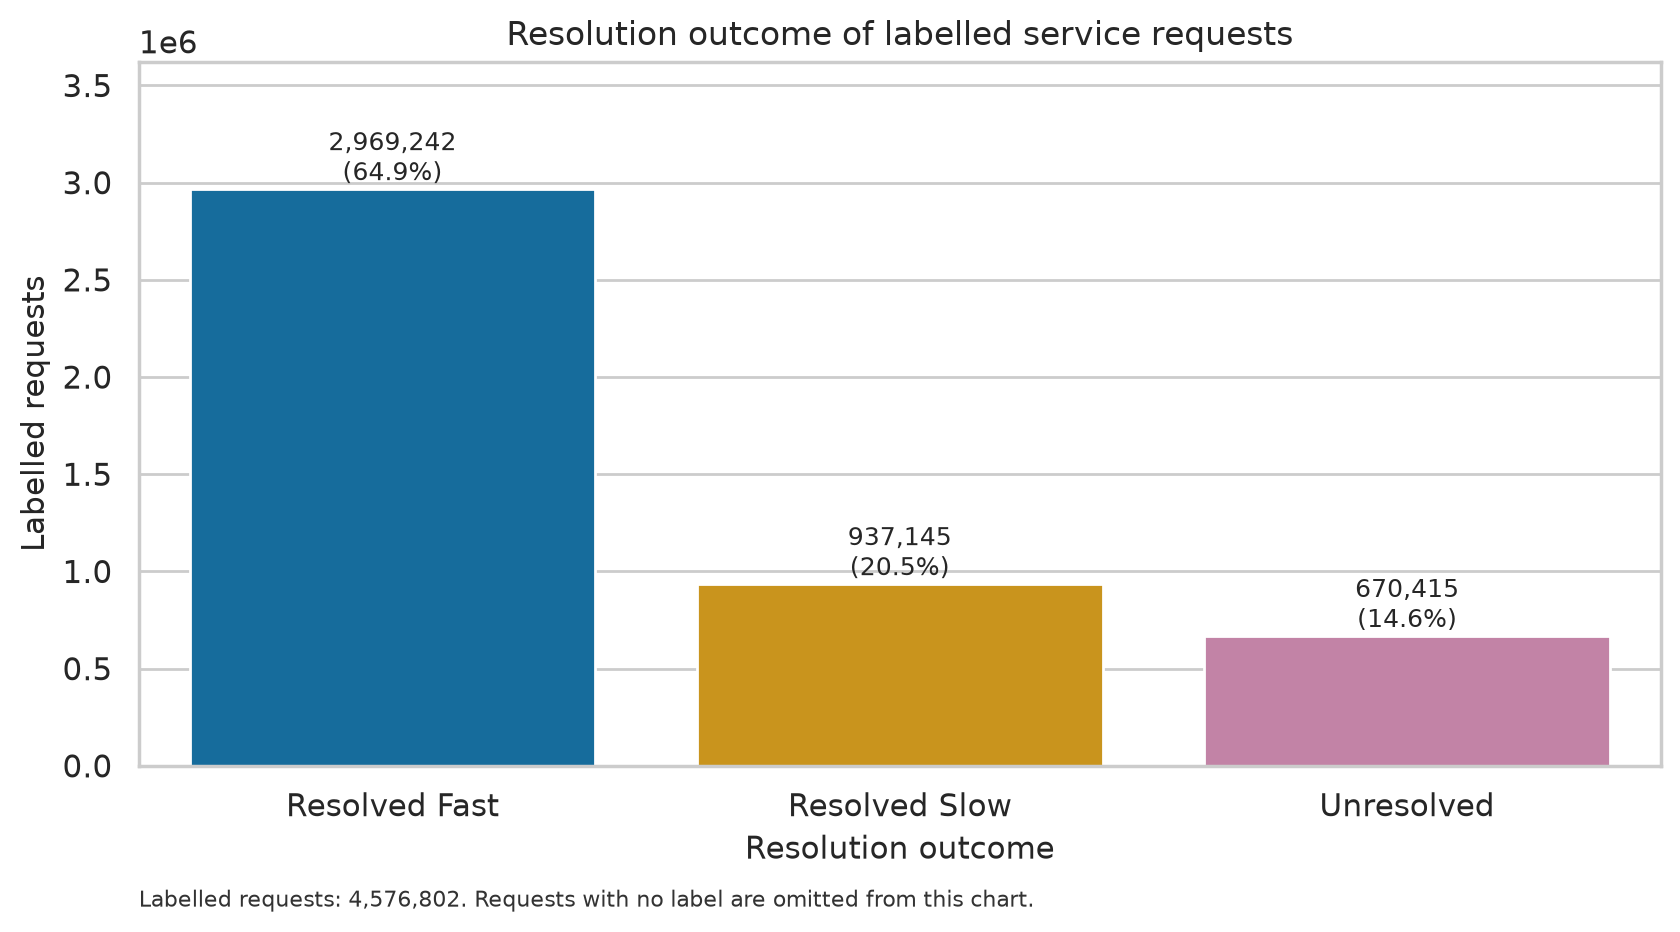

In [3]:
target = eda.target_distribution(frame)
target_path = config.TABLES_DIR / "03_target_distribution.csv"
target.to_csv(target_path, index=False)
print(target_path)
display(percent_view(target, digits=2))

_figure, figure_path = visualization.plot_target_distribution(target)
print(figure_path)
display(Image(filename=str(figure_path)))


### Finding

Of the 4,576,802 labelled requests, 2,969,242 (64.9%) are Resolved Fast, 937,145 (20.5%) are Resolved Slow, and 670,415 (14.6%) are Unresolved. Another 16,001 analysis rows have no label.

Resolved Fast is the majority class. A later accuracy score would mostly reflect that majority. Macro-F1, which gives each class the same weight, matches the project metric better. Resolved Slow and Unresolved are the classes a service department would want to catch, and together they are about 35% of labelled requests.

Part of the imbalance comes from the seven-day cut. Among completed requests the median duration is 2 days and the 75th percentile is 7 days, so most recorded completions fall on the fast side of this provisional rule. Unresolved is a different kind of outcome: the request had no usable completion on or before 6 October 2026 and was already at least seven days old. Some of those requests may have been completed after this deprecated extract was published.

The 16,001 unlabelled rows are 15,981 open requests younger than seven days and 20 rows whose completion date is earlier than the creation date. They are excluded from the bars so that a recent open request is not shown as a failure.


## 4. Figure 2 — Missingness and data quality

Predictor missingness is counted on the analysis file. A blank completion date is counted separately, because an open request is supposed to have no completion date. `duration_flag` is empty for ordinary durations; that empty flag is a coding choice and is not treated as missing data.

Duplicate removal happened before this file was written. That count is read from the Phase 2 cleaning log. The other quality counts are recomputed here.


/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_predictor_missingness.csv
/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_completion_status.csv
/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_data_quality.csv
Subcouncil stored as '0': 8,465


,column,display_name,missing_count,missing_percent,kind
0,Sub_Council,Subcouncil,201272,4.38,genuine_missing
1,Ward,Ward,81551,1.78,genuine_missing
2,Suburb,Suburb,45107,0.98,genuine_missing
3,C3_Complaint_Type,Complaint type,0,0.00,genuine_missing
4,Work_Center,Work centre,0,0.00,genuine_missing
5,Created_On_Date,Created on date,0,0.00,genuine_missing
6,Notifications_Created,Notifications created,3587,0.08,genuine_missing


,status,display_name,requests,percent_of_analysis_file,kind
0,completion_recorded,Recorded completion,3906387,85.05,duration_known
1,blank_unresolved,Open at least 7 days (Unresolved),670415,14.60,meaningful_blank
2,blank_insufficient_follow_up,Open fewer than 7 days (no label),15981,0.35,meaningful_blank
3,completion_before_creation,Completion before creation (excluded),20,0.00,invalid_date


,item,description,requests,source,percent_of_analysis_file
0,analysis_rows,Rows in the analysis file,4592803,analysis_file,100.00
1,exact_business_duplicates_removed,Exact duplicate business rows removed before t...,779663,phase2_cleaning_log,
2,labelled_rows,Rows with a resolution class,4576802,analysis_file,99.65
3,insufficient_follow_up,Open requests excluded because they are younge...,15981,analysis_file,0.35
4,completion_before_creation,Rows excluded because completion is earlier th...,20,analysis_file,0.00
5,unusual_long_duration,"Completed requests longer than 365 days, retained",14953,analysis_file,0.33
6,repeated_notification_id_rows,Rows that still share a notification id after ...,309758,analysis_file,6.74
7,suburb_placeholder_hash,Suburb stored as '#',365919,analysis_file,7.97
8,suburb_generic_town,Suburb stored as 'GENERIC TOWN 0000',4248,analysis_file,0.09
9,subcouncil_not_assigned,Subcouncil stored as 'Not assigned',1622881,analysis_file,35.34


/workspace/evidence/reproducibility/notebooks/isolated/results/figures/03_02_missingness_and_quality.png


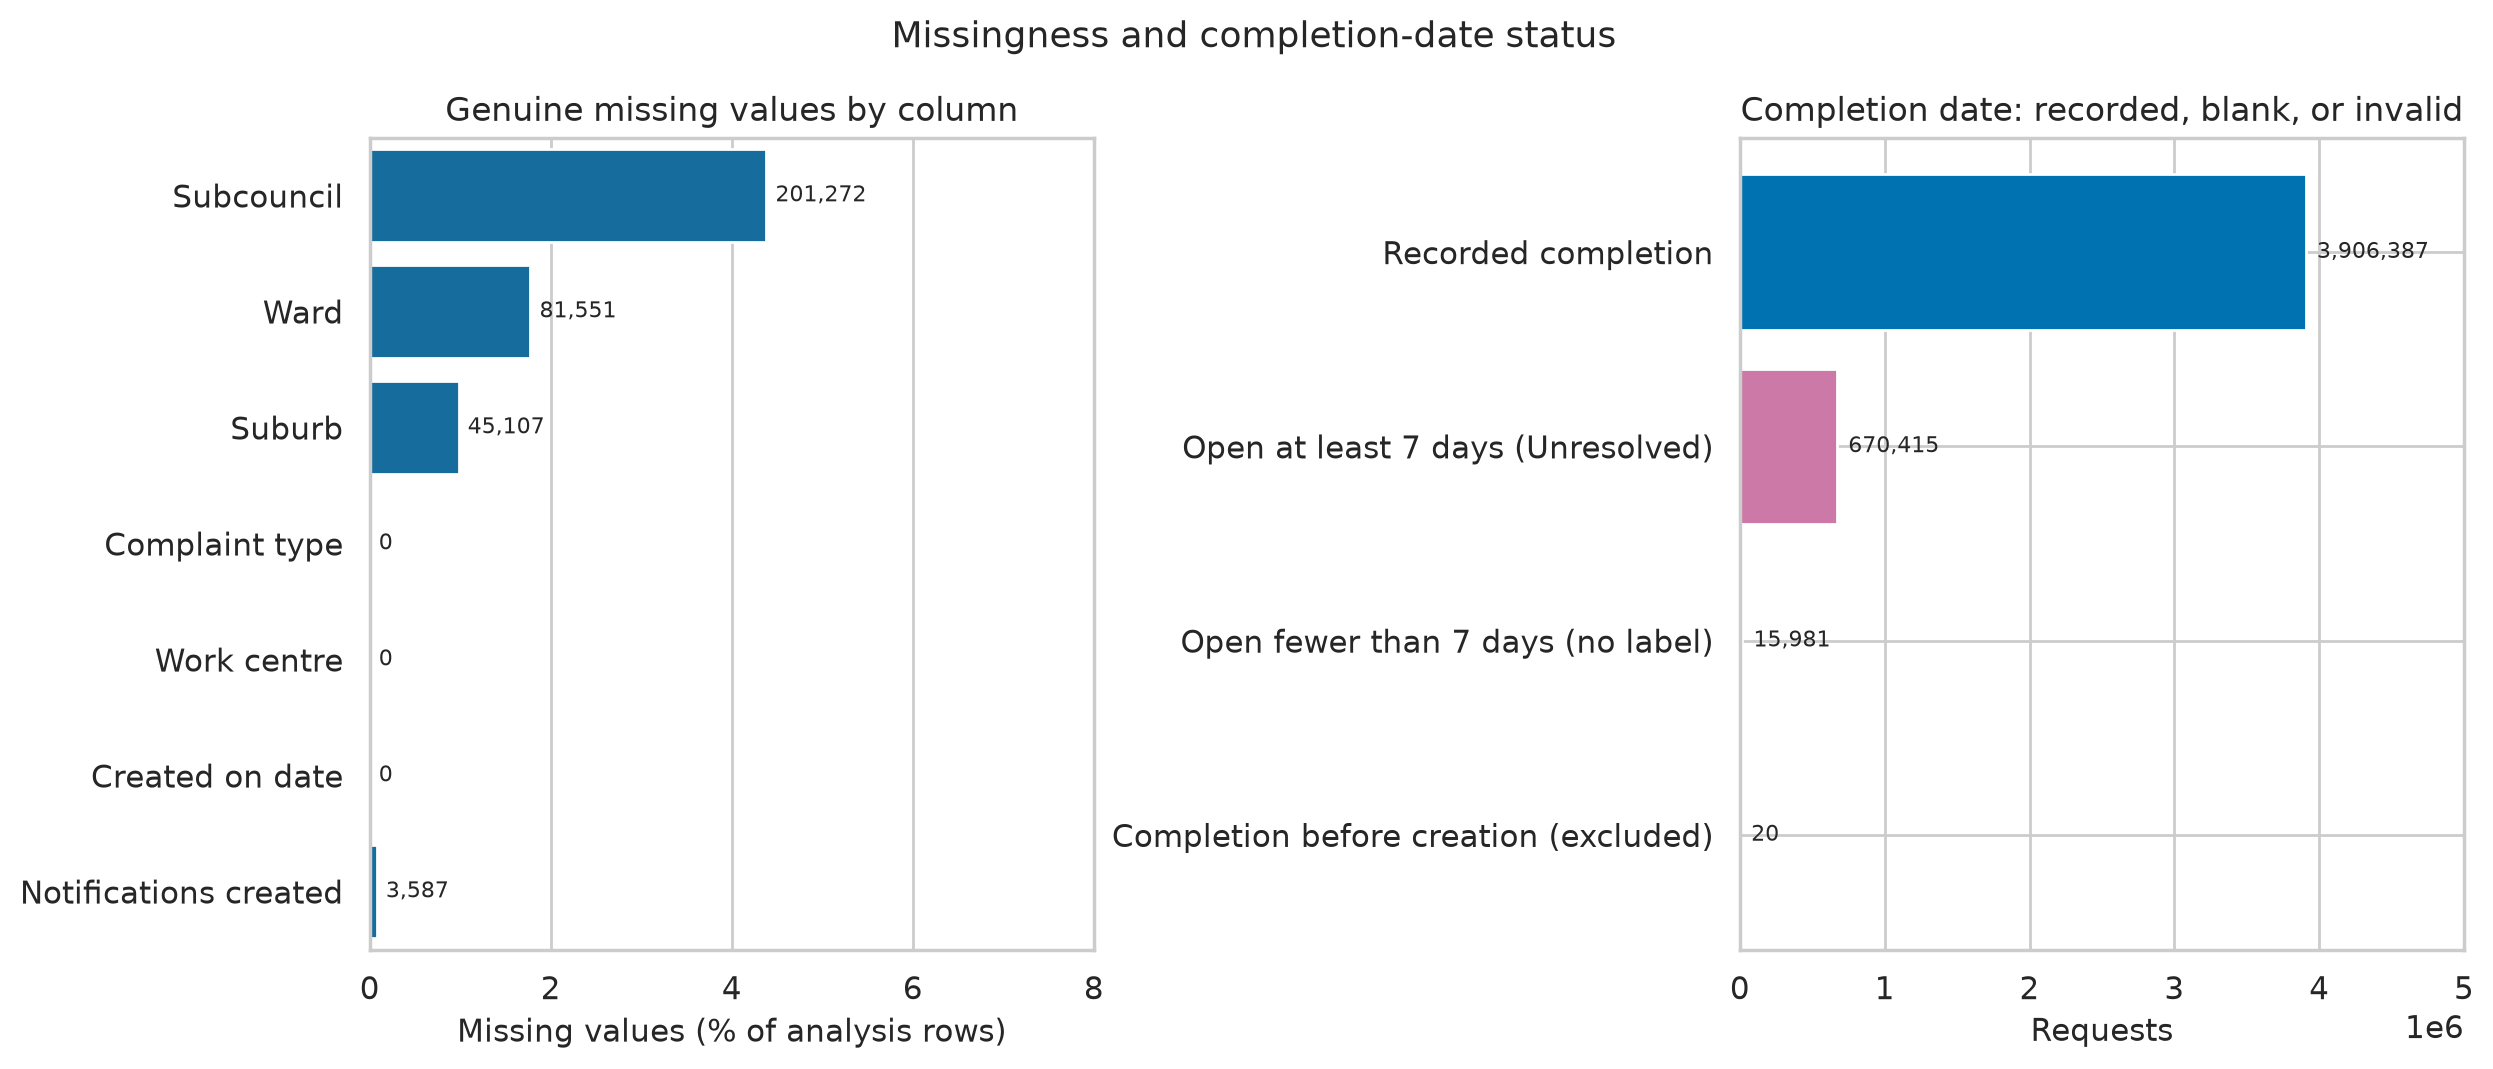

In [4]:
missing = eda.predictor_missingness(frame)
completion = eda.completion_status(frame)
if int(completion["requests"].sum()) != len(frame):
    raise RuntimeError("Completion statuses do not cover every analysis row.")
duplicates_removed = eda.phase2_duplicate_removals(config.TABLES_DIR / "02_cleaning_decisions.csv")
quality = eda.data_quality_table(frame, exact_duplicates_removed=duplicates_removed)

missing_path = config.TABLES_DIR / "03_predictor_missingness.csv"
completion_path = config.TABLES_DIR / "03_completion_status.csv"
quality_path = config.TABLES_DIR / "03_data_quality.csv"
missing.to_csv(missing_path, index=False)
completion.to_csv(completion_path, index=False)
quality.to_csv(quality_path, index=False)
print(missing_path)
print(completion_path)
print(quality_path)
subcouncil_zero = int(frame["Sub_Council"].astype("string").str.strip().eq("0").sum())
print(f"Subcouncil stored as '0': {subcouncil_zero:,}")
display(percent_view(missing, digits=2))
display(percent_view(completion, digits=2))
display(percent_view(quality, digits=2))

_figure, figure_path = visualization.plot_missingness_and_completion(missing, completion)
print(figure_path)
display(Image(filename=str(figure_path)))


### Finding

Complaint type, work centre, and Created On Date have no missing values in the analysis file. Subcouncil is missing on 201,272 rows (4.38%), ward on 81,551 rows (1.78%), and suburb on 45,107 rows (0.98%). Notifications Created is missing on 3,587 rows (0.08%). These blanks are genuine missing predictors.

A blank completion date means something else. Of the 4,592,803 analysis rows, 3,906,387 (85.05%) have a recorded duration. The remaining blanks split into 670,415 open requests that are old enough to be labelled Unresolved (14.60%), 15,981 open requests that are still inside the seven-day window (0.35%), and 20 rows with a completion date earlier than the creation date. The first two groups are meaningful blanks. The 20 date reversals are invalid and stay unlabelled.

Other quality counts, from the table above:

- 779,663 exact duplicate business rows were removed before this file was saved. They are not in the denominator of the percentages.
- 309,758 rows (6.74%) still share a notification id with another row whose other fields differ. Those rows were kept.
- 14,953 completed requests lasted more than 365 days. They remain in the file.
- Suburb is stored as `#` on 365,919 rows (7.97%) and as `GENERIC TOWN 0000` on 4,248 rows. Those values are present, so they are not in the missingness bars, and they do not name a suburb. Subcouncil is stored as `0` on 8,465 rows. The first preview rows pair that code with `GENERIC TOWN 0000`.
- Subcouncil is stored as `Not assigned` on 1,622,881 rows (35.34%).
- The coordinate-quality flag, which does not contain the coordinates themselves, marks 1,035,640 pairs missing (22.55%), 2,515,158 outside the local metre envelope (54.76%), and 1,042,005 inside that envelope (22.69%). The envelope is not an official coordinate reference system.

Operationally, area features need a recorded place name before they can be used. A model that treats `#`, `GENERIC TOWN 0000`, or `Not assigned` as real areas would be fitting placeholders. The limitation is that this notebook does not decide how those placeholders should be grouped.


## 5. Figure 3 — Resolution outcome by work centre

The chart uses a count rule: the 12 work centres with the most labelled requests. Proportions are the share of labelled requests inside each centre. The label at the right of each bar is the group size. Centres with fewer than 100 labelled requests stay in the full table and off the chart, because a percentage in a tiny centre moves sharply when a few requests change.


/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_outcome_by_work_centre.csv
/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_work_centre_figure.csv
Work centres among labelled requests: 2,075
Top 12 requests: 1,415,810 (30.9% of labelled requests)
Centres with fewer than 100 labelled requests: 1,216 (21,425 requests, 0.47% of labelled requests)


resolution_outcome,rank,Work_Center,Resolved Fast,Resolved Slow,Unresolved,requests,Resolved Fast percent,Resolved Slow percent,Unresolved percent,selection_rule
0,1,Energy,184066,80005,30416,294487,62.5,27.2,10.3,largest 12 groups by labelled request count
1,2,Electricity - FLR-Vanguard-Contractor,118029,15753,5372,139154,84.8,11.3,3.9,largest 12 groups by labelled request count
2,3,Electricity - FLR-Wynberg-Contractor,97168,10960,6293,114421,84.9,9.6,5.5,largest 12 groups by labelled request count
3,4,Electricity - FLR-M'Plain-Contractor,92665,12685,6470,111820,82.9,11.3,5.8,largest 12 groups by labelled request count
4,5,Pinelands Sewer Depot Dispatch,81663,21280,7059,110002,74.2,19.3,6.4,largest 12 groups by labelled request count
5,6,Electricity - FLR-Gugulethu-Contractor,83834,11733,12751,108318,77.4,10.8,11.8,largest 12 groups by labelled request count
6,7,WSR- CTA Debt Management,100873,1309,1433,103615,97.4,1.3,1.4,largest 12 groups by labelled request count
7,8,Electricity - FLR-Muizenberg-Contractor,81604,9372,6166,97142,84.0,9.6,6.3,largest 12 groups by labelled request count
8,9,Electricity - FLR-Mowbray-Contractor,83396,7853,3993,95242,87.6,8.2,4.2,largest 12 groups by labelled request count
9,10,Impuma Collections,60669,13114,9880,83663,72.5,15.7,11.8,largest 12 groups by labelled request count


Highest Unresolved shares among centres with at least 5,000 labelled requests:


resolution_outcome,Work_Center,Resolved Fast,Resolved Slow,Unresolved,requests,Resolved Fast percent,Resolved Slow percent,Unresolved percent
90,Revenue Protection East,34,103,9136,9273,0.4,1.1,98.5
131,WCSB Meter Mgt STA 020,78,205,4929,5212,1.5,3.9,94.6
133,PH: Carpentry: Ndabeni,46,577,4549,5172,0.9,11.2,88.0
76,Reinst Reg 4 Wat T/O,51,1525,11334,12910,0.4,11.8,87.8
134,PH: Multiskilled: Heideveld,135,623,4348,5106,2.6,12.2,85.2


Highest Resolved Slow shares among centres with at least 5,000 labelled requests:


resolution_outcome,Work_Center,Resolved Fast,Resolved Slow,Unresolved,requests,Resolved Fast percent,Resolved Slow percent,Unresolved percent
110,Vending Investigations & Correspondence,23,6510,526,7059,0.3,92.2,7.5
50,Revenue Protection - Tech Support: Audit,3277,20399,66,23742,13.8,85.9,0.3
74,Do not use,1106,11135,1303,13544,8.2,82.2,9.6
135,KRN Completed Jobs,790,3776,488,5054,15.6,74.7,9.7
121,Health -Noise Pollution,171,4752,1561,6484,2.6,73.3,24.1


/workspace/evidence/reproducibility/notebooks/isolated/results/figures/03_03_outcome_by_work_centre.png


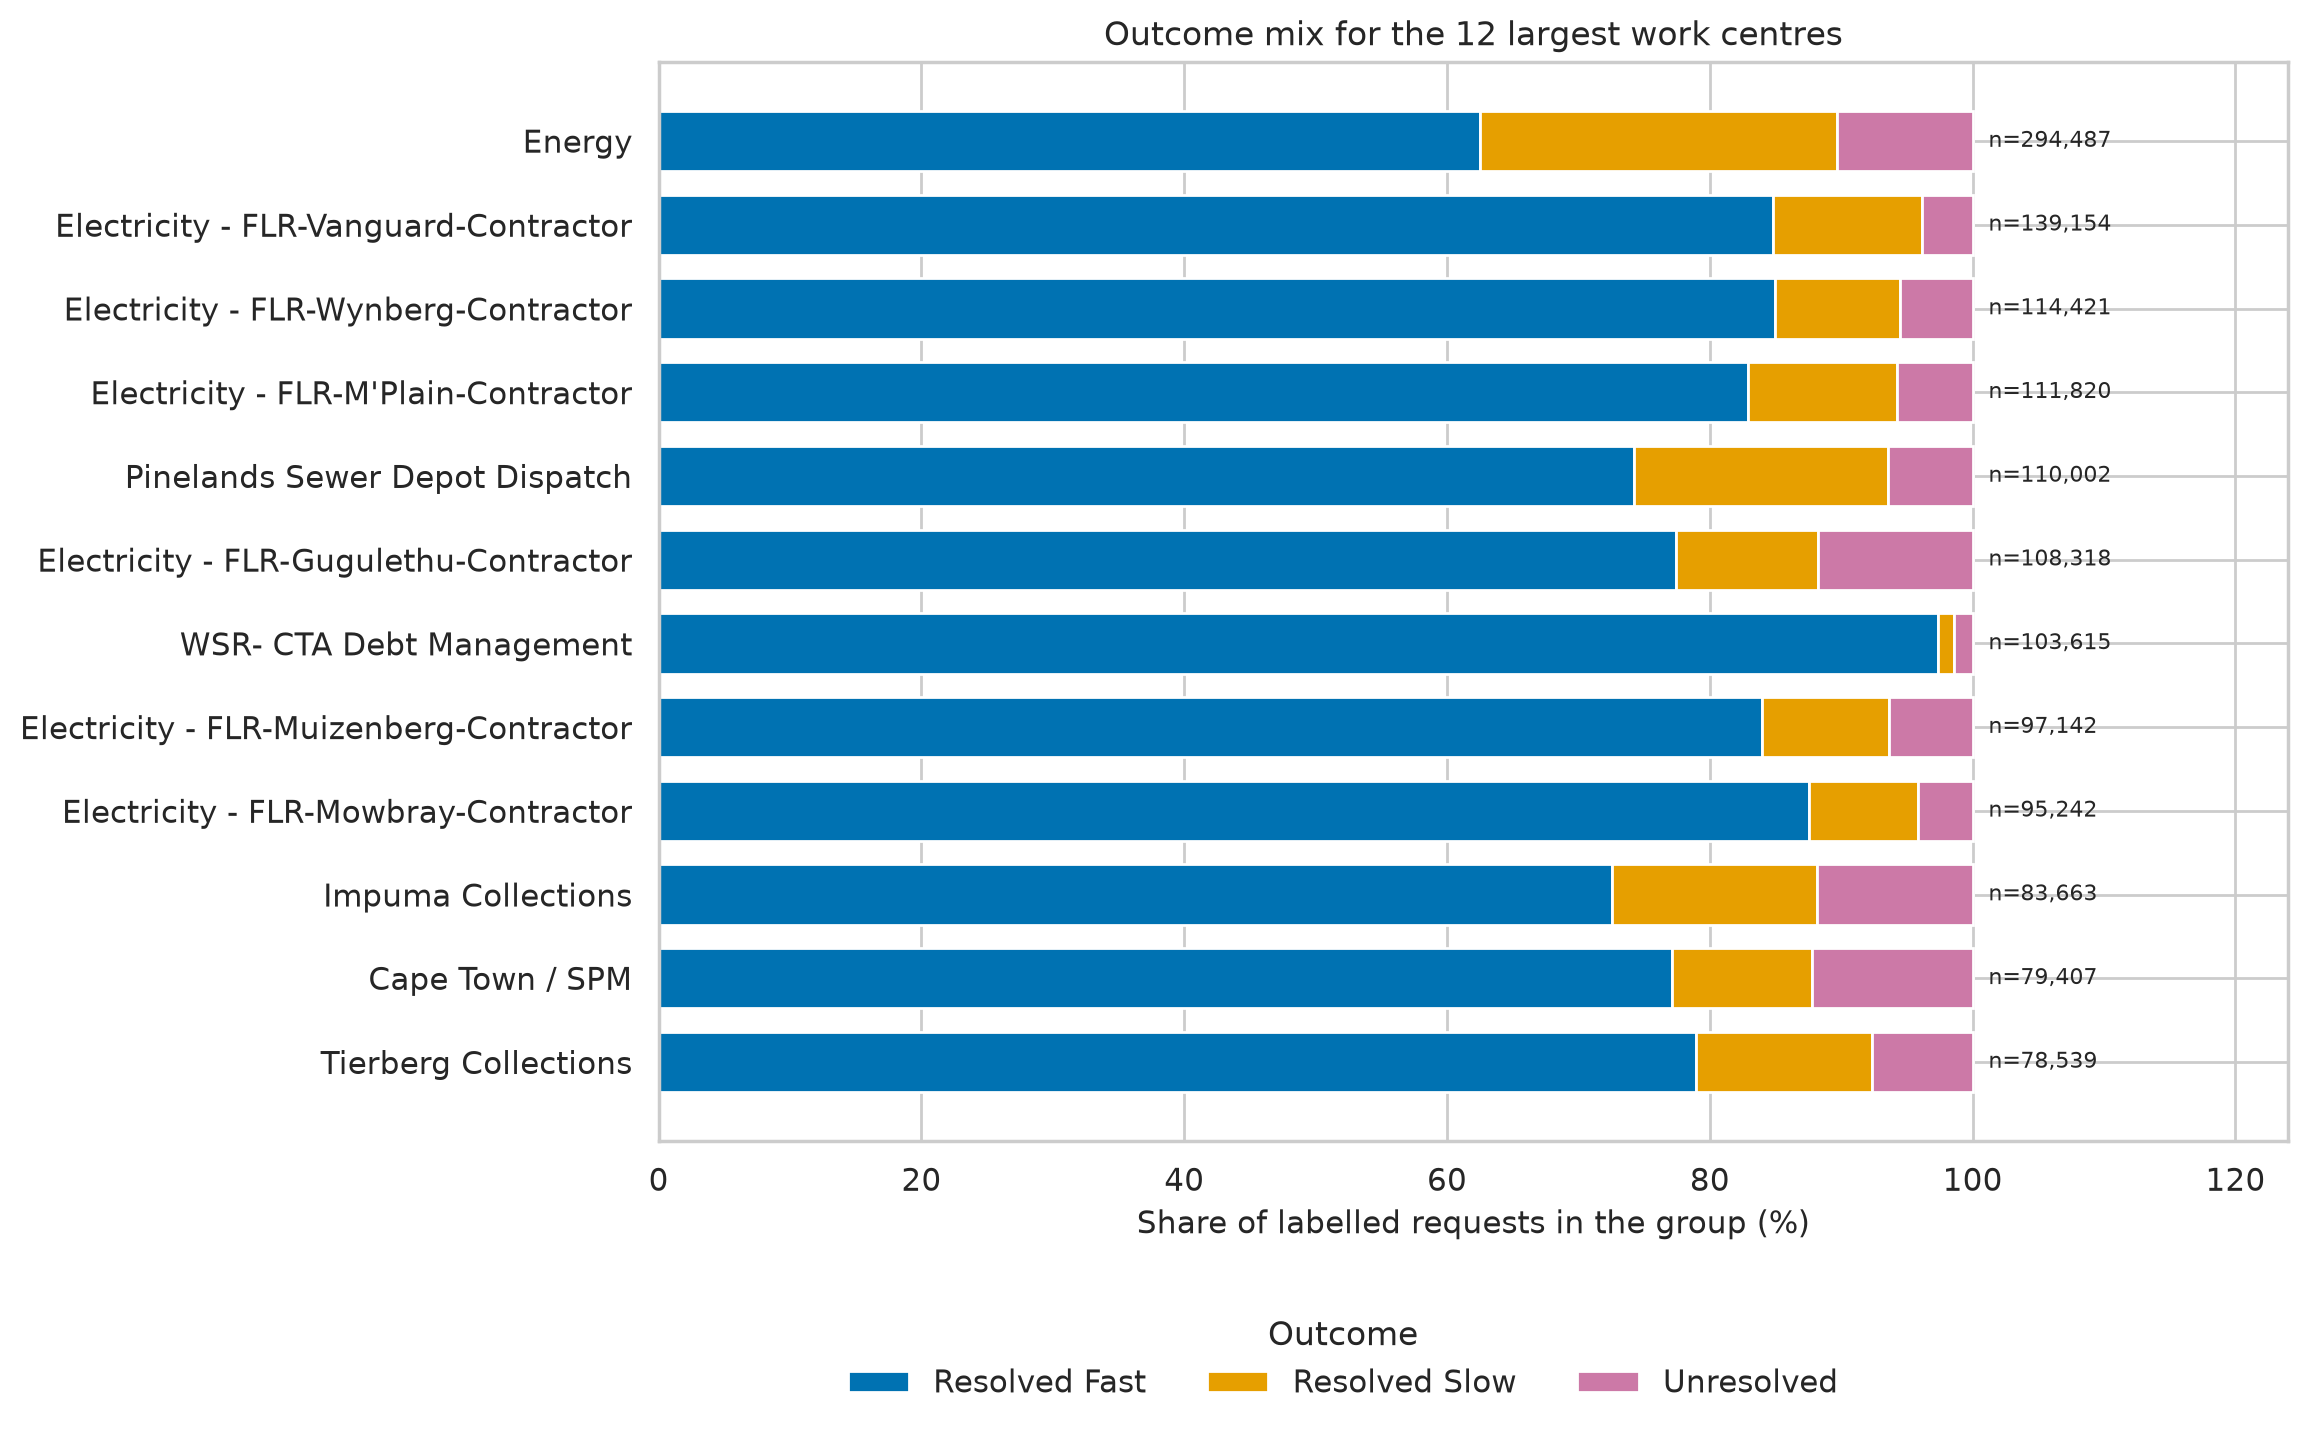

In [5]:
work = eda.group_outcomes(frame, "Work_Center")
work_top = eda.largest_groups(work, top_n=eda.DEFAULT_TOP_GROUPS)
work_small = eda.small_group_summary(work, minimum_requests=eda.SMALL_GROUP_REQUESTS)
work_path = config.TABLES_DIR / "03_outcome_by_work_centre.csv"
work_top_path = config.TABLES_DIR / "03_work_centre_figure.csv"
work.to_csv(work_path, index=False)
work_top.to_csv(work_top_path, index=False)
labelled_requests = int(work["requests"].sum())
print(work_path)
print(work_top_path)
print(f"Work centres among labelled requests: {len(work):,}")
print(f"Top 12 requests: {int(work_top['requests'].sum()):,} ({work_top['requests'].sum() / labelled_requests * 100:.1f}% of labelled requests)")
print(
    "Centres with fewer than "
    f"{work_small['minimum_requests']} labelled requests: {work_small['small_groups']:,} "
    f"({work_small['requests_in_small_groups']:,} requests, "
    f"{work_small['percent_of_labelled_in_small_groups']:.2f}% of labelled requests)"
)
display(percent_view(work_top))

large_centres = work.loc[work["requests"] >= 5000]
print("Highest Unresolved shares among centres with at least 5,000 labelled requests:")
display(percent_view(large_centres.sort_values("Unresolved percent", ascending=False).head(5)))
print("Highest Resolved Slow shares among centres with at least 5,000 labelled requests:")
display(percent_view(large_centres.sort_values("Resolved Slow percent", ascending=False).head(5)))

figure, figure_path = visualization.plot_outcome_by_group(
    work_top,
    "Work_Center",
    "Outcome mix for the 12 largest work centres",
    "03_03_outcome_by_work_centre.png",
)
print(figure_path)
display(Image(filename=str(figure_path)))


### Finding

There are 2,076 work centres in the analysis file and 2,075 among labelled requests. The 12 largest cover 1,415,810 labelled requests, which is 30.9% of labelled requests. Volume is concentrated, and it is also spread out: 1,216 centres have fewer than 100 labelled requests and together hold only 21,425 requests (0.47%). Those small centres are a weak basis for a percentage comparison.

Among the 12 largest, Energy has 294,487 labelled requests, with 62.5% Resolved Fast, 27.2% Resolved Slow, and 10.3% Unresolved. The electricity first-line contractor centres are faster than Energy on this cut: Vanguard is 84.8% Resolved Fast, Wynberg 84.9%, M'Plain 82.9%, Gugulethu 77.4%, Muizenberg 84.0%, and Mowbray 87.6%. Pinelands Sewer Depot Dispatch (110,002 requests) is 74.2% Resolved Fast and 19.3% Resolved Slow. WSR- CTA Debt Management (103,615 requests) is 97.4% Resolved Fast. That mix looks like a short administrative queue sitting next to field depots. The chart shows the difference; it does not show whether the centre name was known at the moment the request was logged. Phase 2 left work centre in the candidate list with that warning still open.

Outside the top 12, some large centres have a very different mix. Among centres with at least 5,000 labelled requests, Revenue Protection East is 98.5% Unresolved (9,273 requests) and Reinst Reg 4 Wat T/O is 87.8% Unresolved (12,910 requests). Vending Investigations & Correspondence is 92.2% Resolved Slow (7,059 requests), and the centre stored as `Do not use` is 82.2% Resolved Slow (13,544 requests). A retired or administrative name can dominate a rate. Group size is printed so those rates are read with the denominator.


## 6. Figure 4 — Resolution outcome by complaint type

The same count rule selects the complaint types: the 12 types with the most labelled requests. The full type table is saved, and types with at least 10,000 labelled requests are shown again so a slower category that is common, but outside the top 12, is still visible.


/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_outcome_by_complaint_type.csv
/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_complaint_type_figure.csv
/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_complaint_types_at_least_10000.csv
Complaint types among labelled requests: 1,153
Top 12 requests: 2,014,815 (44.0% of labelled requests)
Types with at least 10,000 labelled requests: 77
Duplicate unresolved count: 3 of 73,682


resolution_outcome,rank,C3_Complaint_Type,Resolved Fast,Resolved Slow,Unresolved,requests,Resolved Fast percent,Resolved Slow percent,Unresolved percent,selection_rule
0,1,No Power,427556,29401,17861,474818,90.0,6.2,3.8,largest 12 groups by labelled request count
1,2,SEW: Blocked/Overflow,342180,93578,35360,471118,72.6,19.9,7.5,largest 12 groups by labelled request count
2,3,Street Lights - All Lights Out,113872,62521,23451,199844,57.0,31.3,11.7,largest 12 groups by labelled request count
3,4,Street Lights - Single Light Out,126511,39359,23400,189270,66.8,20.8,12.4,largest 12 groups by labelled request count
4,5,Damaged Bin - 240L,85850,22864,13966,122680,70.0,18.6,11.4,largest 12 groups by labelled request count
5,6,Stolen Bins - 240L,82131,19594,12571,114296,71.9,17.1,11.0,largest 12 groups by labelled request count
6,7,Suspect Tampering,12828,37774,32880,83482,15.4,45.2,39.4,largest 12 groups by labelled request count
7,8,WAT: Leak in Road/Pavement/Undergr,34534,28350,16332,79216,43.6,35.8,20.6,largest 12 groups by labelled request count
8,9,Duplicate,26024,47655,3,73682,35.3,64.7,0.0,largest 12 groups by labelled request count
9,10,MTR: Customer Reconnection Request,71288,254,320,71862,99.2,0.4,0.4,largest 12 groups by labelled request count


Highest Resolved Slow shares among types with at least 10,000 labelled requests:


resolution_outcome,C3_Complaint_Type,Resolved Fast,Resolved Slow,Unresolved,requests,Resolved Fast percent,Resolved Slow percent,Unresolved percent
44,DO NOT USE (Plumbing),3508,13427,1666,18601,18.9,72.2,9.0
33,DO NOT USE (Tree Complaint),2020,19634,6082,27736,7.3,70.8,21.9
8,Duplicate,26024,47655,3,73682,35.3,64.7,0.0
26,PPM KRN Fault,4837,22835,9560,37232,13.0,61.3,25.7
39,Plumbing,3227,12785,5653,21665,14.9,59.0,26.1
56,DO NOT USE (Carpentry,678,7444,7113,15235,4.5,48.9,46.7
6,Suspect Tampering,12828,37774,32880,83482,15.4,45.2,39.4
66,WAT: Leak at Valve,4114,5183,3659,12956,31.8,40.0,28.2


Highest Unresolved shares among types with at least 10,000 labelled requests:


resolution_outcome,C3_Complaint_Type,Resolved Fast,Resolved Slow,Unresolved,requests,Resolved Fast percent,Resolved Slow percent,Unresolved percent
70,Doors: Internal / External,522,1095,10469,12086,4.3,9.1,86.6
58,Carpentry,645,3957,10294,14896,4.3,26.6,69.1
25,WAT: Re-instatement,2966,9811,27039,39816,7.4,24.6,67.9
40,Tree Trimming,1756,6050,13833,21639,8.1,28.0,63.9
22,Meter Replacement Project,1187,16429,25049,42665,2.8,38.5,58.7
51,MTR: Customer Rebate Request,2731,6434,8096,17261,15.8,37.3,46.9


/workspace/evidence/reproducibility/notebooks/isolated/results/figures/03_04_outcome_by_complaint_type.png


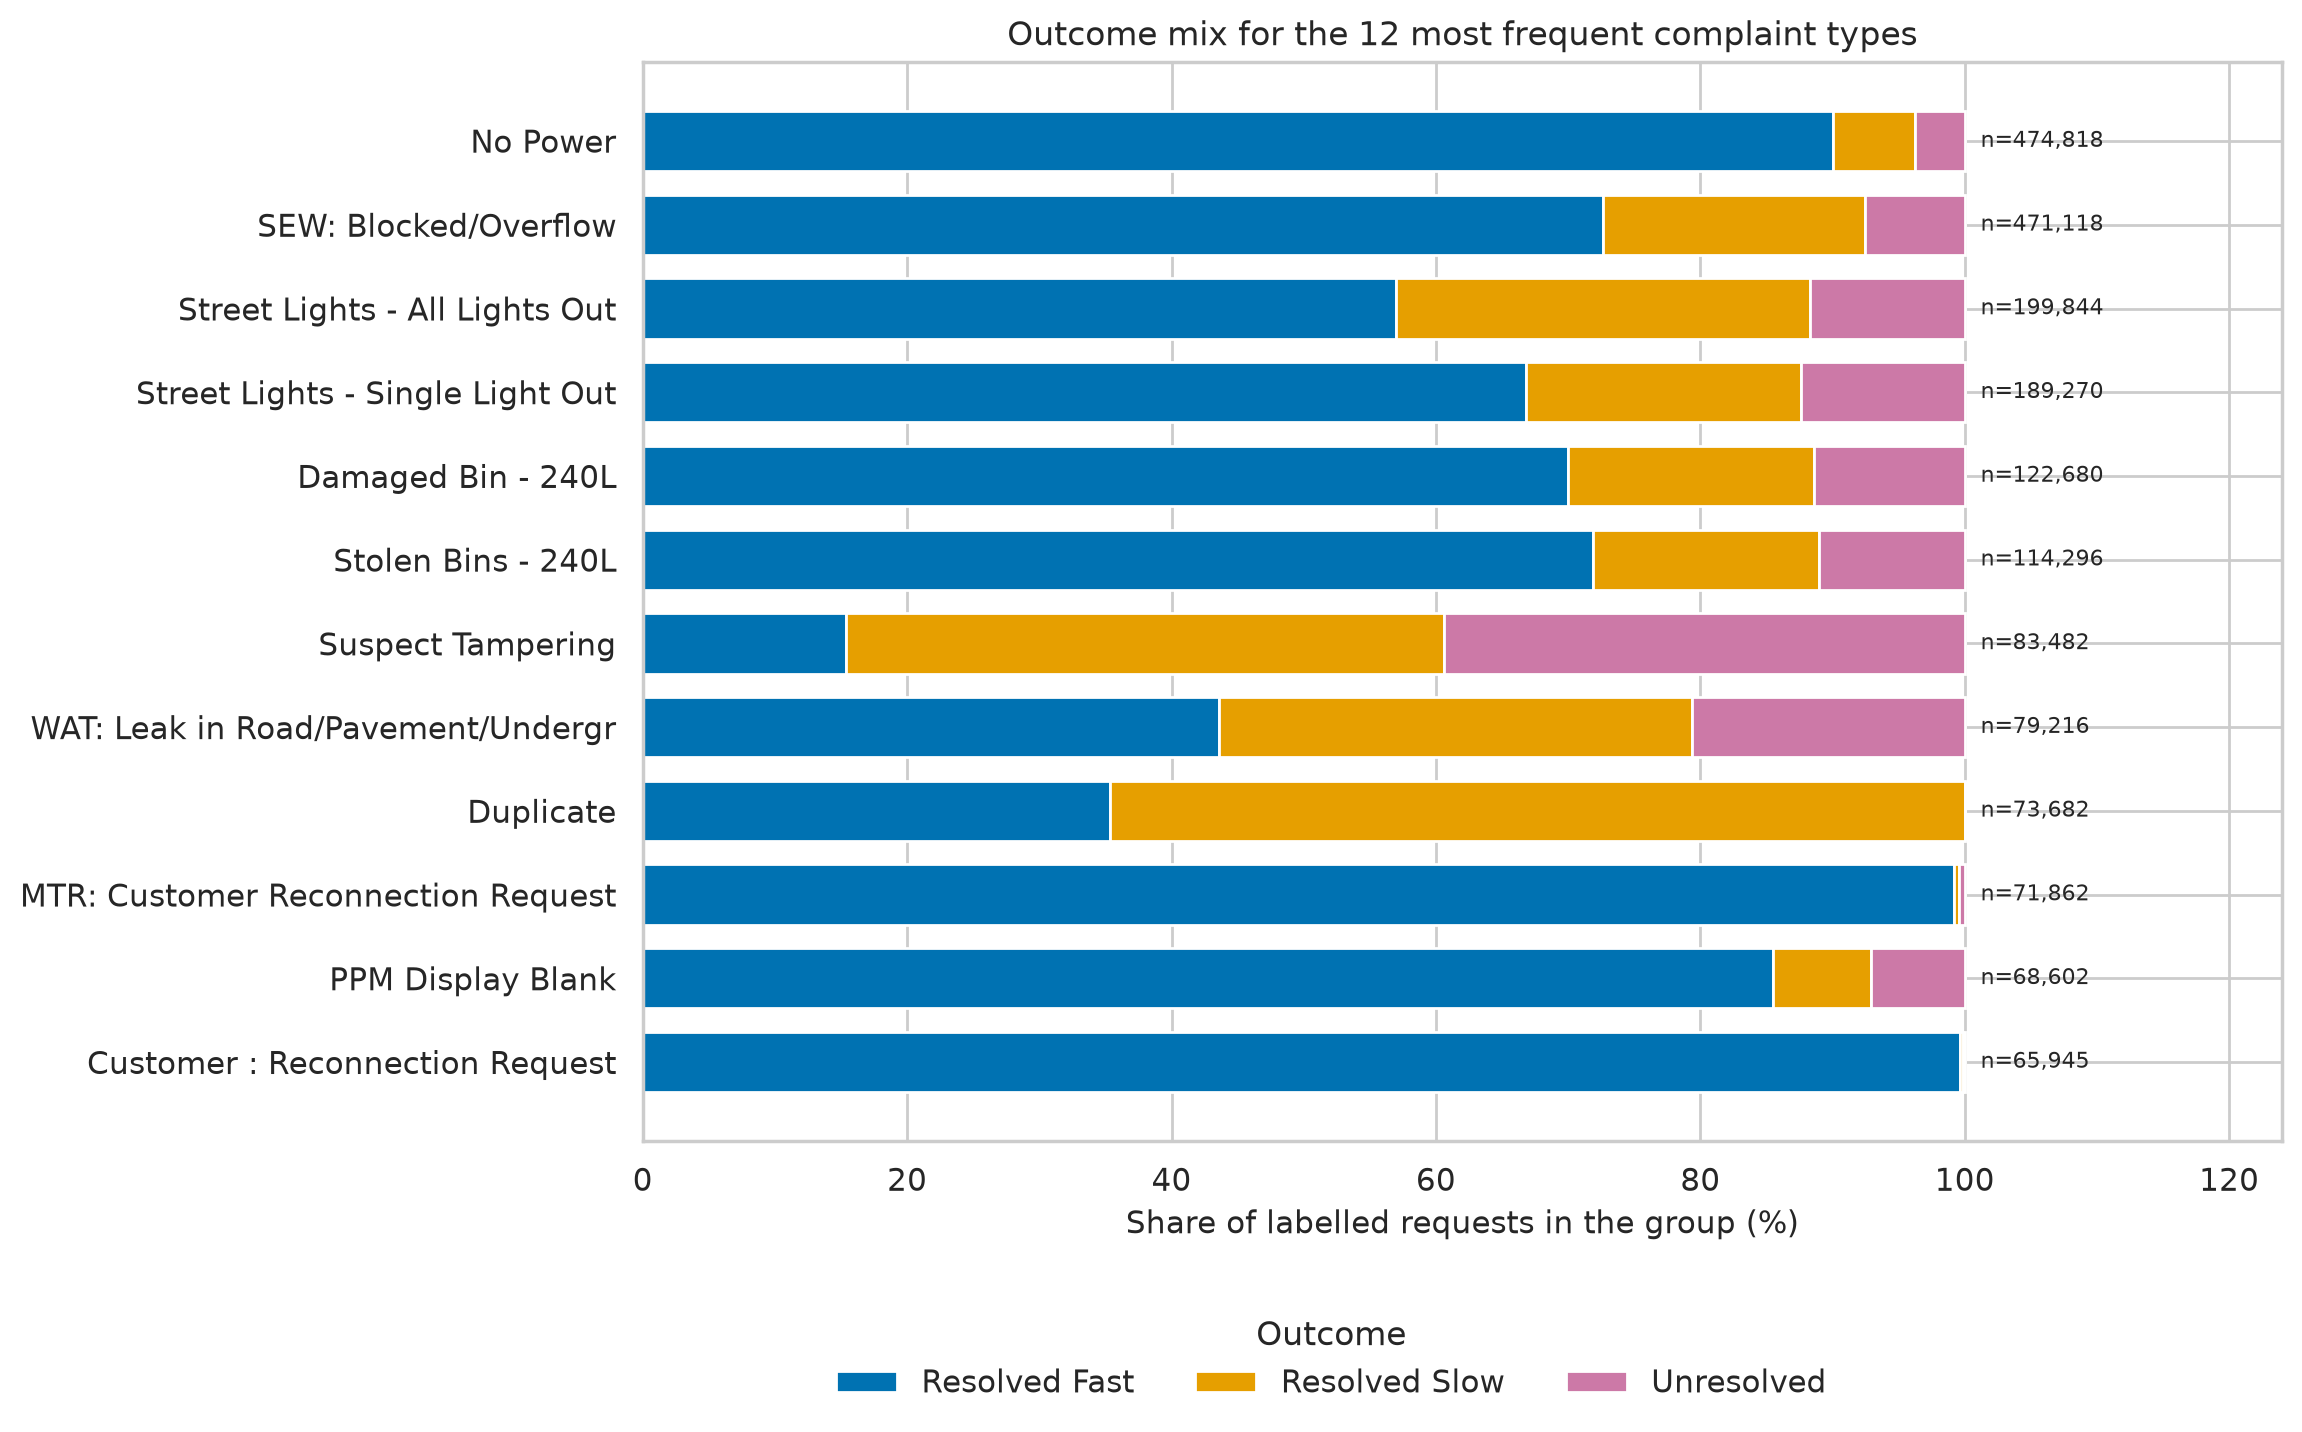

In [6]:
complaints = eda.group_outcomes(frame, "C3_Complaint_Type")
complaint_top = eda.largest_groups(complaints, top_n=eda.DEFAULT_TOP_GROUPS)
complaint_path = config.TABLES_DIR / "03_outcome_by_complaint_type.csv"
complaint_top_path = config.TABLES_DIR / "03_complaint_type_figure.csv"
frequent_path = config.TABLES_DIR / "03_complaint_types_at_least_10000.csv"
complaints.to_csv(complaint_path, index=False)
complaint_top.to_csv(complaint_top_path, index=False)
frequent = complaints.loc[complaints["requests"] >= 10000].sort_values("requests", ascending=False)
frequent.to_csv(frequent_path, index=False)
labelled_requests = int(complaints["requests"].sum())
print(complaint_path)
print(complaint_top_path)
print(frequent_path)
print(f"Complaint types among labelled requests: {len(complaints):,}")
print(
    f"Top 12 requests: {int(complaint_top['requests'].sum()):,} "
    f"({complaint_top['requests'].sum() / labelled_requests * 100:.1f}% of labelled requests)"
)
print(f"Types with at least 10,000 labelled requests: {len(frequent):,}")
duplicate = complaints.loc[complaints["C3_Complaint_Type"].eq("Duplicate")]
if len(duplicate) == 1:
    duplicate_row = duplicate.iloc[0]
    print(
        "Duplicate unresolved count: "
        f"{int(duplicate_row['Unresolved']):,} of {int(duplicate_row['requests']):,}"
    )
display(percent_view(complaint_top))
print("Highest Resolved Slow shares among types with at least 10,000 labelled requests:")
display(percent_view(frequent.sort_values("Resolved Slow percent", ascending=False).head(8)))
print("Highest Unresolved shares among types with at least 10,000 labelled requests:")
display(percent_view(frequent.sort_values("Unresolved percent", ascending=False).head(6)))

figure, figure_path = visualization.plot_outcome_by_group(
    complaint_top,
    "C3_Complaint_Type",
    "Outcome mix for the 12 most frequent complaint types",
    "03_04_outcome_by_complaint_type.png",
)
print(figure_path)
display(Image(filename=str(figure_path)))


### Finding

There are 1,154 complaint types in the analysis file and 1,153 among labelled requests. The 12 most frequent cover 2,014,815 labelled requests, 44.0% of the labelled file.

No Power is the largest type, with 474,818 labelled requests and 90.0% Resolved Fast. The two reconnection types in the top 12 are faster still: MTR: Customer Reconnection Request is 99.2% Resolved Fast (71,862 requests) and Customer : Reconnection Request is 99.7% Resolved Fast (65,945 requests). Sewer blockages (SEW: Blocked/Overflow, 471,118 requests) are 72.6% Resolved Fast and 19.9% Resolved Slow, close to the overall slow share of 20.5%.

Longer outcomes show up in other frequent types. Street Lights - All Lights Out (199,844 requests) is 31.3% Resolved Slow. Suspect Tampering (83,482 requests) is 15.4% Resolved Fast, 45.2% Resolved Slow, and 39.4% Unresolved. WAT: Leak in Road/Pavement/Undergr (79,216 requests) is 35.8% Resolved Slow and 20.6% Unresolved. These categories are where a seven-day completion is less common.

Duplicate (73,682 requests) is 64.7% Resolved Slow, and only 3 of those requests are Unresolved. The stored name behaves like a category that almost always receives a completion, often after seven days. The table does not say what process produces that name.

Among types with at least 10,000 labelled requests, several names that begin `DO NOT USE` have high Resolved Slow shares. DO NOT USE (Plumbing) is 72.2% Resolved Slow (18,601 requests) and DO NOT USE (Tree Complaint) is 70.8% Resolved Slow (27,736 requests). High Unresolved shares in that same size band include Doors: Internal / External at 86.6% (12,086 requests), Carpentry at 69.1% (14,896 requests), WAT: Re-instatement at 67.9% (39,816 requests), and Meter Replacement Project at 58.7% (42,665 requests). Retired names and project-style names are still in the extract, so a complaint-type feature will need a grouping rule before modelling. This notebook records the rates and does not build that grouping.


## 7. Figure 5 — Monthly request volume

A map is not drawn. The coordinate reference system was not verified in Phase 2, most coordinate pairs are missing or outside the local metre envelope, and the coordinates were withheld from the analysis file. Suburb is also a weak map substitute at this stage: 44,905 distinct values, with `#` stored on 365,919 rows.

The figure therefore shows time. The upper panel counts every analysis row by the month of Created On Date, including rows with no label. A month inside the date span with zero requests is marked. The lower panel is the outcome mix among labelled requests only, so the unlabelled recent requests do not appear as Unresolved.


/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_monthly_volume.csv
Months in the span: 46
Months with no created requests: 2025-01
Median requests in a month that has rows: 104,427
Smallest months with rows:


,month,requests,labelled_requests,insufficient_follow_up
32,2025-09,500,500,0
45,2026-10,20294,7170,13124
25,2025-02,33496,33496,0


Largest month:


,month,requests,labelled_requests
15,2024-04,200348,200348


July and August 2024, and the thin September 2025:


,month,requests,gap,labelled_requests,insufficient_follow_up,resolved_fast,resolved_fast_percent,resolved_slow,resolved_slow_percent,unresolved,unresolved_percent
18,2024-07,130058,False,130058,0,78288,60.2,49357,37.9,2413,1.9
19,2024-08,121429,False,121429,0,78051,64.3,41157,33.9,2221,1.8
32,2025-09,500,False,500,0,452,90.4,38,7.6,10,2.0


From May 2026 to the end of the extract:


,month,requests,gap,labelled_requests,insufficient_follow_up,resolved_fast,resolved_fast_percent,resolved_slow,resolved_slow_percent,unresolved,unresolved_percent
40,2026-05,145542,False,145542,0,81290,55.9,8104,5.6,56148,38.6
41,2026-06,138725,False,138725,0,80486,58.0,4298,3.1,53941,38.9
42,2026-07,105680,False,105680,0,53692,50.8,2456,2.3,49532,46.9
43,2026-08,102659,False,102659,0,43226,42.1,1017,1.0,58416,56.9
44,2026-09,104786,False,101929,2857,36729,36.0,0,0.0,65200,64.0
45,2026-10,20294,False,7170,13124,7170,100.0,0,0.0,0,0.0


2024-03: 104,328 requests
C3_Complaint_Type
SEW: Blocked/Overflow               10971
No Power                             7794
Duplicate                            5151
Street Lights - All Lights Out       4099
Street Lights - Single Light Out     3649

2024-04: 200,348 requests
C3_Complaint_Type
SEW: Blocked/Overflow               23016
No Power                            17839
Duplicate                           11693
Street Lights - All Lights Out      10286
Street Lights - Single Light Out     9412

September 2026 recorded durations: 36,729 completed, maximum 2 days
October 2026: 20,294 created, 7,170 labelled, 13,124 inside the observation window


/workspace/evidence/reproducibility/notebooks/isolated/results/figures/03_05_monthly_request_volume.png


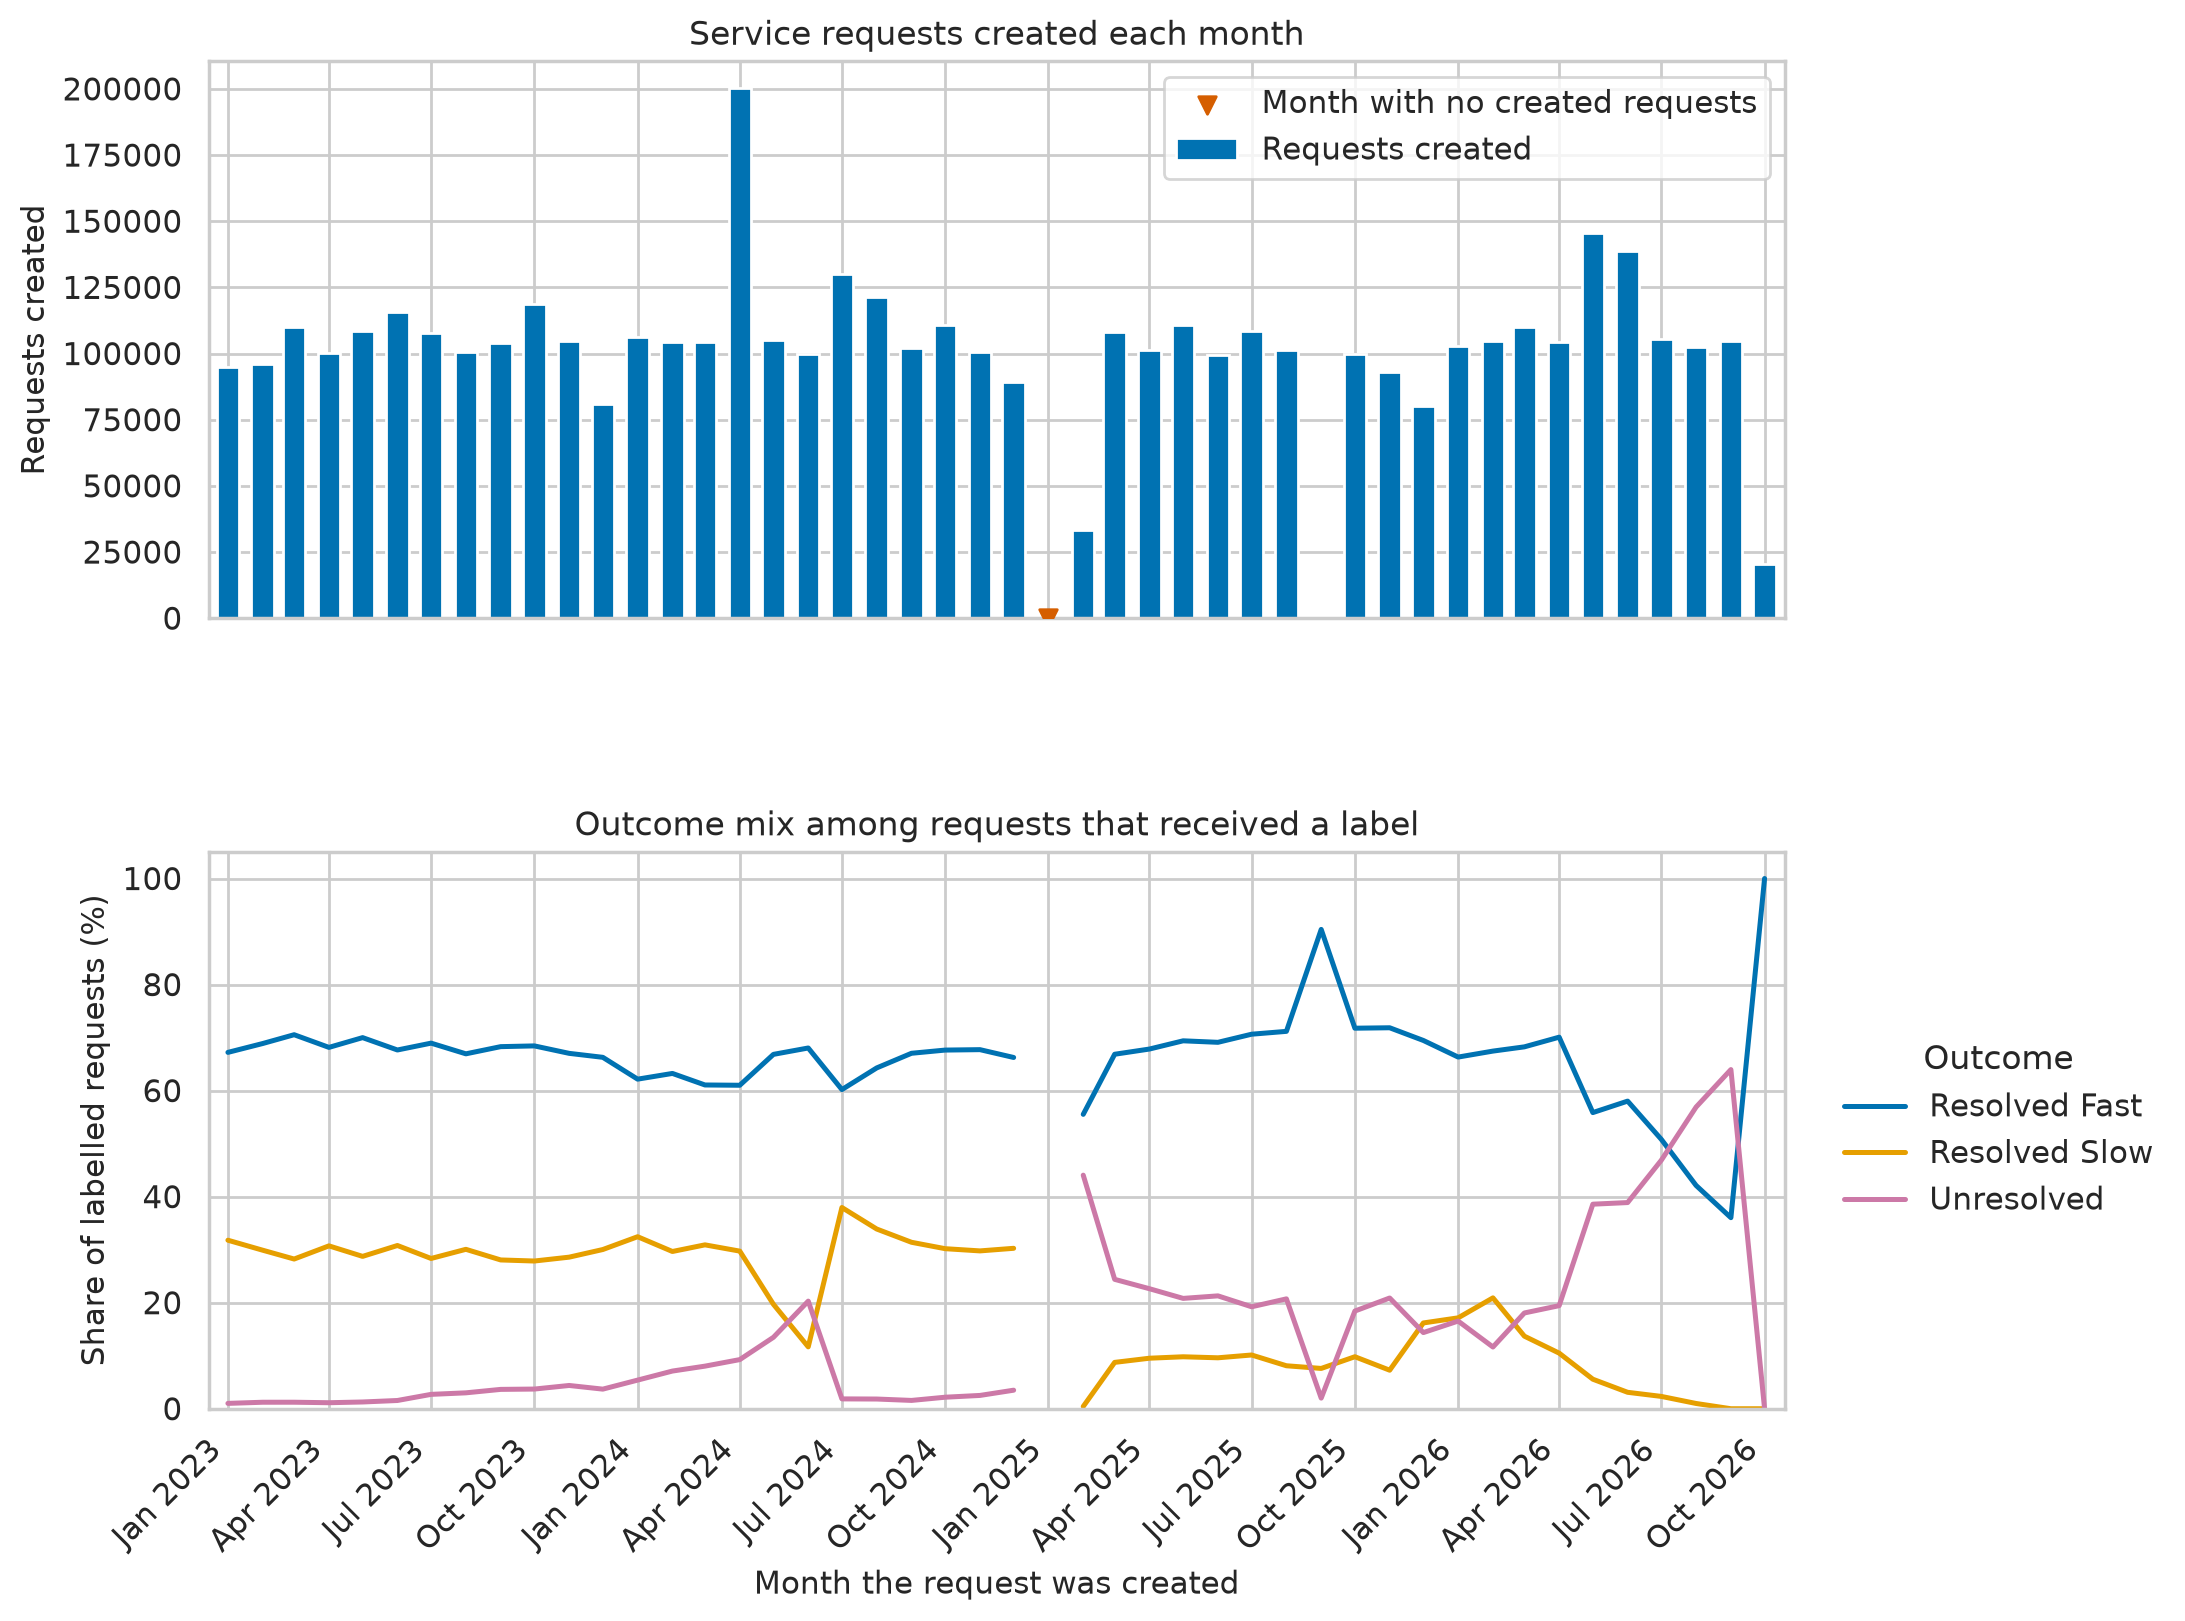

In [7]:
monthly = eda.monthly_activity(frame)
monthly_path = config.TABLES_DIR / "03_monthly_volume.csv"
monthly.to_csv(monthly_path, index=False)
present = monthly.loc[~monthly["gap"]]
print(monthly_path)
print(f"Months in the span: {len(monthly)}")
print("Months with no created requests:", ", ".join(monthly.loc[monthly["gap"], "month"]) or "none")
print(f"Median requests in a month that has rows: {int(present['requests'].median()):,}")
print("Smallest months with rows:")
display(present.nsmallest(3, "requests")[["month", "requests", "labelled_requests", "insufficient_follow_up"]])
print("Largest month:")
display(present.nlargest(1, "requests")[["month", "requests", "labelled_requests"]])
print("July and August 2024, and the thin September 2025:")
display(percent_view(monthly.loc[monthly["month"].isin(["2024-07", "2024-08", "2025-09"])]))
print("From May 2026 to the end of the extract:")
tail = monthly.loc[monthly["month"] >= "2026-05"]
display(percent_view(tail))

created_month = frame["Created_On_Date"].dt.to_period("M").astype(str)
for month in ("2024-03", "2024-04"):
    counts = frame.loc[created_month.eq(month), "C3_Complaint_Type"].value_counts().head(5)
    print(f"{month}: {int(created_month.eq(month).sum()):,} requests")
    print(counts.to_string())
    print()

september_days = frame.loc[created_month.eq("2026-09"), "resolution_days"].dropna()
print(
    "September 2026 recorded durations: "
    f"{len(september_days):,} completed, maximum {september_days.max():.0f} days"
)
october = monthly.loc[monthly["month"].eq("2026-10")].iloc[0]
print(
    "October 2026: "
    f"{int(october['requests']):,} created, "
    f"{int(october['labelled_requests']):,} labelled, "
    f"{int(october['insufficient_follow_up']):,} inside the observation window"
)

_figure, figure_path = visualization.plot_monthly_patterns(monthly)
print(figure_path)
display(Image(filename=str(figure_path)))


### Finding

Created On Date runs from 1 January 2023 to 6 October 2026, which is 46 calendar months. January 2025 has no rows. The neighbouring months are December 2024 (89,218 requests) and February 2025 (33,496 requests). September 2025 has 500 requests. The median month that does contain rows has 104,427 requests, so February 2025 is about one third of a typical month and September 2025 is almost empty. These are gaps in the extract. This notebook does not establish whether the live system also had no requests in January 2025.

April 2024 is the high month, with 200,348 requests, compared with 104,328 in March 2024. The leading types in both months are sewer blockages, no power, Duplicate, and street lights. The April increase is spread across the usual categories.

July 2024 (130,058 requests) moves the other way on the outcome mix: Resolved Slow is 37.9% and Unresolved is 1.9%. August 2024 (121,429 requests) is still 33.9% Resolved Slow and 1.8% Unresolved. September 2025 is the sharp peak on the lower panel, at 90.4% Resolved Fast, and that percentage is computed from 500 requests.

The outcome mix is stable through the earlier years and then changes near the export date. In May 2026, 38.6% of labelled requests are Unresolved. That share rises to 46.9% in July, 56.9% in August, and 64.0% in September (65,200 of 101,929 labelled September requests). September has 0 Resolved Slow rows. The 36,729 September requests with a recorded duration were all completed within 2 days. A Resolved Slow label was available for a September request completed in 8 to 35 days and still on or before 6 October 2026, and no such completion is stored.

October 2026 contains 20,294 requests, all created on or before 6 October. Of those, 13,124 are inside the seven-day window and have no label. The 7,170 labelled October requests are all Resolved Fast, because only a completion inside those few observed days can receive a label. The lower panel therefore hits 100% Resolved Fast in October because the other outcomes cannot occur yet.

The late rise in Unresolved is tied to the right-hand edge of a frozen extract. It is a weak estimate of a lasting change in service performance. A later train/test split that ignores the export date would treat this edge effect as if it were a stable class difference.


## 8. Resolution time, long durations, and volume

The duration chart uses completed requests only. The bins are calendar days from Created On Date to Completed Date, as stored in `resolution_days`. Requests without a completion stay out of this chart; they were counted in Figure 2. Durations above 365 days stay in the last bin and in the file.


/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_duration_bins.csv
/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_extreme_durations.csv
/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_extreme_durations_by_complaint.csv
/workspace/evidence/reproducibility/notebooks/isolated/results/tables/03_extreme_durations_by_work_centre.csv
Median labelled requests per work centre: 45


,bin,requests,percent_of_completed
0,Same calendar day (0 days),1129914,28.9
1,1 day,723924,18.5
2,2 to 7 days,1115404,28.6
3,8 to 30 days,532950,13.6
4,31 to 90 days,232304,5.9
5,91 to 365 days,156938,4.0
6,More than 365 days,14953,0.4


,metric,value
0,completed_requests,3906387.0
1,median_days,2.0
2,p75_days,7.0
3,p90_days,32.0
4,p99_days,236.0
5,maximum_days,1135.0
6,same_calendar_day,1129914.0
7,within_7_days,2969242.0
8,longer_than_365_days,14953.0
9,longer_than_730_days,3075.0


Complaint types with the most durations over 365 days:


,C3_Complaint_Type,requests
0,Meter Replacement Project,1716
1,DO NOT USE (Electrical),1670
2,DO NOT USE (Carpentry,1554
3,WAT: Re-instatement,1553
4,PPM KRN Fault,981
5,DO NOT USE (Plumbing),737
6,EPIC Roads,644
7,DO NOT USE (Tree Complaint),486
8,Street Lights - All Lights Out,385
9,Other,366


Work centres with the most durations over 365 days:


,Work_Center,requests
0,Do not use,1156
1,Electricity-PTM-Projects,1039
2,Reinst Reg 4 Wat T/O,973
3,PH: Electrical Maintenance R2 & R4,704
4,Revenue Protection - Tech Support: Audit,582
5,Hillstar Water: DM(Do not use),576
6,Energy,554
7,Reinst Reg 3 Wat T/O,365
8,Hillstar Water Depot Dispatch 1 FLR,348
9,TRAFFIC SIGNALS,315


/workspace/evidence/reproducibility/notebooks/isolated/results/figures/03_06_resolution_duration.png


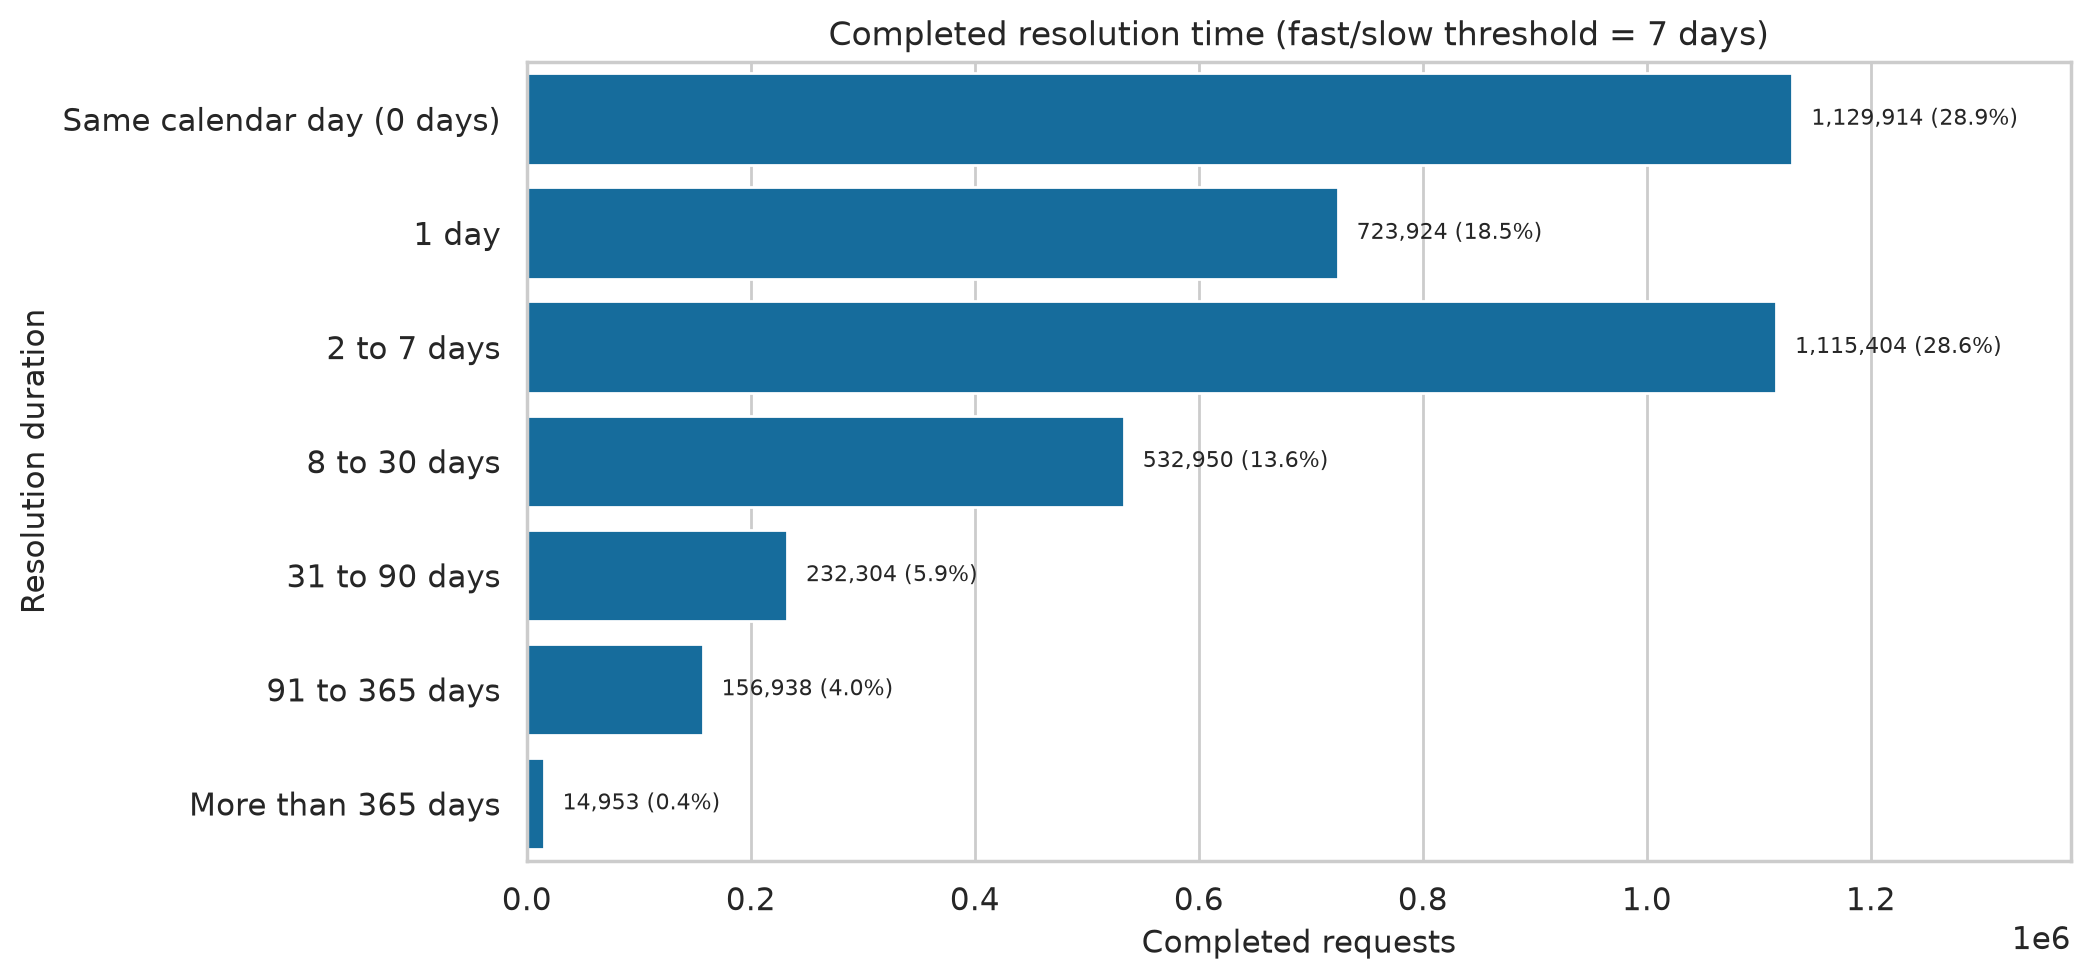

In [8]:
durations = eda.duration_distribution(frame)
extremes = eda.extreme_duration_tables(frame)
duration_path = config.TABLES_DIR / "03_duration_bins.csv"
extreme_path = config.TABLES_DIR / "03_extreme_durations.csv"
extreme_complaint_path = config.TABLES_DIR / "03_extreme_durations_by_complaint.csv"
extreme_centre_path = config.TABLES_DIR / "03_extreme_durations_by_work_centre.csv"
durations.to_csv(duration_path, index=False)
extremes["summary"].to_csv(extreme_path, index=False)
extremes["by_complaint_type"].to_csv(extreme_complaint_path, index=False)
extremes["by_work_centre"].to_csv(extreme_centre_path, index=False)
print(duration_path)
print(extreme_path)
print(extreme_complaint_path)
print(extreme_centre_path)
print(f"Median labelled requests per work centre: {work['requests'].median():.0f}")
display(percent_view(durations))
display(extremes["summary"])
print("Complaint types with the most durations over 365 days:")
display(extremes["by_complaint_type"])
print("Work centres with the most durations over 365 days:")
display(extremes["by_work_centre"])

_figure, figure_path = visualization.plot_duration_bins(durations, config.FAST_SLOW_THRESHOLD_DAYS)
print(figure_path)
display(Image(filename=str(figure_path)))


### Finding

There are 3,906,387 completed requests. The median duration is 2 days, the 75th percentile is 7 days, the 90th is 32 days, and the 99th is 236 days. The maximum is 1,135 days.

Same-calendar-day completion accounts for 1,129,914 requests, 28.9% of completed requests. The source stores dates and not times, so a request opened and closed on the same date has duration 0 whatever the number of hours between them. Another 1,115,404 completed requests (28.6%) took 2 to 7 days. Together with the 723,924 one-day completions, 2,969,242 completed requests (76.0%) fall on the Resolved Fast side of the seven-day cut. That count matches the Resolved Fast total, because Resolved Fast is defined as a recorded duration of seven days or less.

The tail is real in the file and is small relative to the body: 156,938 completions (4.0%) took 91 to 365 days, and 14,953 (0.4%) took more than 365 days. Of those long completions, 3,075 exceeded 730 days and 300 exceeded 1,000 days. The complaint types that contribute the most rows over 365 days include Meter Replacement Project (1,716), DO NOT USE (Electrical) (1,670), DO NOT USE (Carpentry (1,554), and WAT: Re-instatement (1,553). Long duration is therefore mixed with project work and with categories whose names say not to use them. Those rows are retained. Deleting them would hide the part of the service record this audit was meant to see.

Work-centre volume is in Figure 3 and in `results/tables/03_outcome_by_work_centre.csv`. Energy is the largest labelled centre (294,487 requests). Most centres are small: the median centre has 45 labelled requests, and 1,216 centres have fewer than 100.


## 9. EDA findings for the report

The labelled extract can support a three-class description, with two limits that should travel into the later modelling notebooks.

1. **Class balance.** Labelled requests are 64.9% Resolved Fast, 20.5% Resolved Slow, and 14.6% Unresolved (2,969,242, 937,145, and 670,415). Macro-F1 is the appropriate headline metric. Accuracy alone would reward a fast-only prediction. Recall for Resolved Slow and Unresolved is the operational focus.

2. **The seven-day cut matches the completed-duration distribution and is still provisional.** Median completed duration is 2 days and the 75th percentile is 7 days. Same-calendar-day closures are 28.9% of completions, and the field has no time of day. Changing the cut would move the class sizes.

3. **Blank completion dates are mostly open requests.** 670,415 blanks are Unresolved after at least seven days of observation. 15,981 blanks are too recent to label. 20 rows have a completion date before the creation date. Predictor gaps are smaller: subcouncil 4.38%, ward 1.78%, suburb 0.98%. Placeholders are larger than those gaps: suburb `#` is 7.97% of rows, and subcouncil `Not assigned` is 35.34%.

4. **Complaint type separates fast and slow work in the raw names.** No Power and the reconnection types are mostly Resolved Fast. Street-light failures, water leaks, and Suspect Tampering are slower or more often unresolved. Names beginning `DO NOT USE`, Duplicate, and Meter Replacement Project have their own outcome mixes and need an explicit grouping rule later.

5. **Work centre also separates outcome mixes, and it may not be known at logging.** The 12 largest centres cover 30.9% of labelled requests. Debt management is almost all Resolved Fast. Some revenue-protection and reinstatement centres are mostly Unresolved. 1,216 centres have fewer than 100 labelled requests.

6. **Time is usable, and the last months are censored.** Monthly volume is usually near 104,000 requests. January 2025 is absent, September 2025 has 500 rows (90.4% Resolved Fast on that small base), and April 2024 has 200,348. July 2024, a full month of 130,058 requests, is 37.9% Resolved Slow. From May 2026 the Unresolved share rises, September 2026 has no Resolved Slow completions, and October 2026 can label only the requests that already finished inside a few days. A random split would mix that edge into the test score.

7. **Long durations stay.** 14,953 completions exceed 365 days, and the longest is 1,135 days. They are flagged and kept.

8. **No map is published.** Coordinates are a quality flag only. The reference system is unverified, and suburb text includes a large placeholder.

No model was trained in this notebook.
